# TripletMarginLoss-NetlistGraph

这是使用网表图的新版本，即网表图+正常训练：

In [10]:
import os, sys, itertools
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from hw2vec.config import Config
from hw2vec.hw2graph import *
from tqdm import tqdm
from pytorch_metric_learning import distances, losses, miners, reducers

In [11]:
# dir = ['--yaml_path', '../config/example_gnn4ip.yaml', \
#     #    '--raw_dataset_path', '../../bigcreate/newdatas', \
#     #    '--data_pkl_path', 'pkl/dfg_ip_rt291.pkl', \
#         '--graph_type', 'DFG']
dir = ['--yaml_path', '../config/example_gnn4ip.yaml']
# cfg = Config(sys.argv[1:])
cfg = Config(dir)

In [12]:
cfg.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
cfg.num_feature_dim = 10
cfg.batch_size = 64
cfg.hidden1 = 64
cfg.hidden2 = 128
cfg.embed_dim = 256
cfg.epochs = 200
# cfg.epochs = 100
cfg.learning_rate = 0.01
cfg.dropout = 0.1

## 0 加载数据集

In [13]:
# dataset = torch.load("Reduced-DFG-with_big.pt")
# dataset = torch.load("Reduced-DFG.pt")
dataset = torch.load("NetlistGraph_ITC99_test.pt")

In [14]:
sim_diff_label = []
for data in dataset:
    sim_diff_label.append(data.label)

In [15]:
len(sim_diff_label)

317

In [16]:
for data in dataset:
    data = data.to(cfg.device)

In [17]:
len(dataset)

317

In [18]:
# trainset, testset = train_test_split(dataset, train_size = int(len(dataset) * cfg.ratio), shuffle=True, stratify=None, random_state=cfg.seed)
trainset, testset = train_test_split(dataset, \
                                     train_size = int(len(dataset) * cfg.ratio), \
                                     shuffle=True, \
                                     stratify=None, \
                                     random_state=cfg.seed)

In [19]:
len(trainset)

253

In [20]:
len(testset)

64

---

构造训练集（`train_loader`）：

In [21]:
# train_loader = DataLoader(trainset, shuffle=True, batch_size=cfg.batch_size)
train_loader = DataLoader(dataset, shuffle=True, batch_size=cfg.batch_size)  # testset used during training

---

构造测试集（`test_loader`）：

测试集中的图完全没有在训练时出现过

In [22]:
test_pairs = []
for idx_graph_a, idx_graph_b in itertools.combinations(range(len(testset)), 2):  # testset
    test_pairs.append((testset[idx_graph_a], testset[idx_graph_b]))

SIMILAR = torch.tensor(1, device=cfg.device)
DISSIMILAR = torch.tensor(-1, device=cfg.device)
for pair_idx, pair in enumerate(test_pairs):
    # print(type(all_pairs))
    graph_a, graph_b = pair
    # print(all_pairs[pair_idx], graph_a.hw_type, graph_b.hw_type)
    if graph_a.label == graph_b.label:
        test_pairs[pair_idx] += (SIMILAR,)
    else:
        test_pairs[pair_idx] += (DISSIMILAR,)

In [23]:
test_pairs[0]

(Data(edge_index=[2, 3280], x=[2063, 10], label=3, type='c3540', name='c3540-SL1280'),
 Data(edge_index=[2, 17388], x=[12008, 10], label=7, type='c7552', name='c7552-BR320'),
 tensor(-1, device='cuda:0'))

In [24]:
test_loader = DataLoader(test_pairs, batch_size=cfg.batch_size)

## 1 定义模型

In [25]:
model = GRAPH2VEC(cfg)
convs = [
    GRAPH_CONV("gcn", cfg.num_feature_dim, cfg.hidden1),  # 前者是标签数量，后者是隐藏层
    # GRAPH_CONV("gcn", cfg.hidden, cfg.hidden),
    GRAPH_CONV("gcn", cfg.hidden1, cfg.hidden2)
]
model.set_graph_conv(convs)

# pool = GRAPH_POOL("sagpool", cfg.hidden, cfg.poolratio)
# model.set_graph_pool(pool)

readout = GRAPH_READOUT("mean")
model.set_graph_readout(readout)

output = nn.Linear(cfg.hidden2, cfg.embed_dim)
model.set_output_layer(output)

加载模型参数

In [26]:
# model.load_state_dict(torch.load("triplet_model_notestset.pt"))
model.load_state_dict(torch.load("triplet_model_circuitgraph.pt"))

<All keys matched successfully>

In [27]:
model.to(cfg.device)
trainer = PairwiseGraphTrainer(cfg)
trainer.build(model)

## 2 训练

In [28]:
cfg.trainer = 'triplet'
cfg.epochs = 200
trainer.triplet_train(train_loader)
# trainer.triplet_train(train_loader, mining='all')
# cfg.epochs = 50
# trainer.triplet_train(train_loader, mining='hard')

  0%|          | 1/200 [00:00<02:40,  1.24it/s]

Epoch 0 Iteration 0: Loss = 0.08319541811943054, Number of mined triplets = 535
Epoch 0 Iteration 1: Loss = 0.11568206548690796, Number of mined triplets = 17003
Epoch 0 Iteration 2: Loss = 0.12376284599304199, Number of mined triplets = 12936
Epoch 0 Iteration 3: Loss = 0.11823194473981857, Number of mined triplets = 9496
Epoch 0 Iteration 4: Loss = 0.12206057459115982, Number of mined triplets = 6390


 10%|█         | 21/200 [00:03<00:26,  6.74it/s]

Epoch 20 Iteration 0: Loss = 0.0914500504732132, Number of mined triplets = 4647
Epoch 20 Iteration 1: Loss = 0.08734723925590515, Number of mined triplets = 3052
Epoch 20 Iteration 2: Loss = 0.09643895924091339, Number of mined triplets = 1551
Epoch 20 Iteration 3: Loss = 0.09449660032987595, Number of mined triplets = 2722
Epoch 20 Iteration 4: Loss = 0.09222100675106049, Number of mined triplets = 1600


 20%|██        | 41/200 [00:06<00:24,  6.61it/s]

...

 80%|████████  | 161/200 [00:24<00:05,  6.86it/s]

Epoch 160 Iteration 0: Loss = 0.07346629351377487, Number of mined triplets = 1685
Epoch 160 Iteration 1: Loss = 0.07127782702445984, Number of mined triplets = 2505
Epoch 160 Iteration 2: Loss = 0.04585755616426468, Number of mined triplets = 995
Epoch 160 Iteration 3: Loss = 0.07339082658290863, Number of mined triplets = 1139
Epoch 160 Iteration 4: Loss = 0.061752740293741226, Number of mined triplets = 2034


 90%|█████████ | 181/200 [00:27<00:02,  6.44it/s]

Epoch 180 Iteration 0: Loss = 0.08010829240083694, Number of mined triplets = 428
Epoch 180 Iteration 1: Loss = 0.08159852772951126, Number of mined triplets = 527
Epoch 180 Iteration 2: Loss = 0.08862452208995819, Number of mined triplets = 1179
Epoch 180 Iteration 3: Loss = 0.06315897405147552, Number of mined triplets = 1120
Epoch 180 Iteration 4: Loss = 0.08141332119703293, Number of mined triplets = 554


100%|██████████| 200/200 [00:30<00:00,  6.62it/s]


实践发现hard挖掘会陷入一个局部最优值，loss就不再下降

In [29]:
tsv = os.path.join('losspng','loss_value.csv')
# writer = csv.writer(open(tsv, 'w'))
with open(tsv, 'w') as f:
    writer = csv.writer(f)
    loss1 = trainer.loss_value
    for line in loss1:
        # print(line)
        writer.writerow([line[0], line[1]])

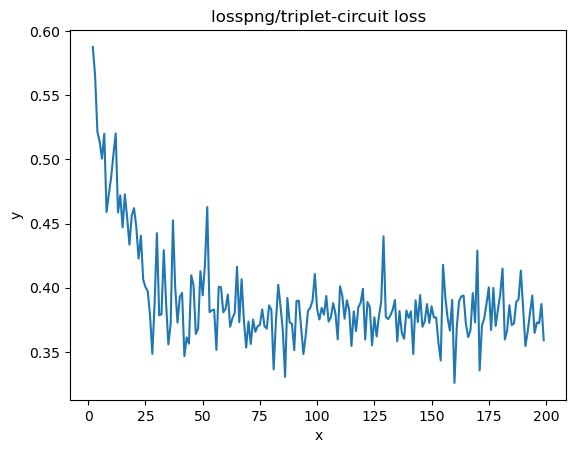

In [30]:
trainer.draw_loss('loss_value.csv','triplet-circuit loss')

In [31]:
cfg.epochs = 150
trainer.triplet_train(train_loader, mining='semihard')
# trainer.triplet_train(train_loader, mining='all')  # not well

  1%|          | 1/150 [00:00<00:22,  6.76it/s]

Epoch 0 Iteration 0: Loss = 0.07822278887033463, Number of mined triplets = 596
Epoch 0 Iteration 1: Loss = 0.08146177977323532, Number of mined triplets = 1349
Epoch 0 Iteration 2: Loss = 0.09468679875135422, Number of mined triplets = 1407
Epoch 0 Iteration 3: Loss = 0.07255882769823074, Number of mined triplets = 557
Epoch 0 Iteration 4: Loss = 0.08412659913301468, Number of mined triplets = 617


 14%|█▍        | 21/150 [00:03<00:18,  6.99it/s]

Epoch 20 Iteration 0: Loss = 0.07860054075717926, Number of mined triplets = 1597
Epoch 20 Iteration 1: Loss = 0.06543188542127609, Number of mined triplets = 653
Epoch 20 Iteration 2: Loss = 0.08414487540721893, Number of mined triplets = 939
Epoch 20 Iteration 3: Loss = 0.06666652113199234, Number of mined triplets = 845
Epoch 20 Iteration 4: Loss = 0.08460874110460281, Number of mined triplets = 1057


 27%|██▋       | 41/150 [00:05<00:15,  6.93it/s]

...

 81%|████████  | 121/150 [00:17<00:04,  6.79it/s]

Epoch 120 Iteration 0: Loss = 0.04662182182073593, Number of mined triplets = 141
Epoch 120 Iteration 1: Loss = 0.08550583571195602, Number of mined triplets = 537
Epoch 120 Iteration 2: Loss = 0.07907596975564957, Number of mined triplets = 485
Epoch 120 Iteration 3: Loss = 0.0946856215596199, Number of mined triplets = 511
Epoch 120 Iteration 4: Loss = 0.09441018849611282, Number of mined triplets = 496


 94%|█████████▍| 141/150 [00:20<00:01,  7.13it/s]

Epoch 140 Iteration 0: Loss = 0.07366341352462769, Number of mined triplets = 1050
Epoch 140 Iteration 1: Loss = 0.09110376983880997, Number of mined triplets = 791
Epoch 140 Iteration 2: Loss = 0.08222158253192902, Number of mined triplets = 395
Epoch 140 Iteration 3: Loss = 0.08053474873304367, Number of mined triplets = 324
Epoch 140 Iteration 4: Loss = 0.07299640029668808, Number of mined triplets = 405


100%|██████████| 150/150 [00:21<00:00,  6.86it/s]


In [32]:
tsv = os.path.join('losspng','loss_value2.csv')
writer = csv.writer(open(tsv, 'w'))
loss2 = trainer.loss_value
loss2 = loss1 + loss2
for index, line in enumerate(loss2, start=1):
    # print(line)
    writer.writerow([index, line[1]])

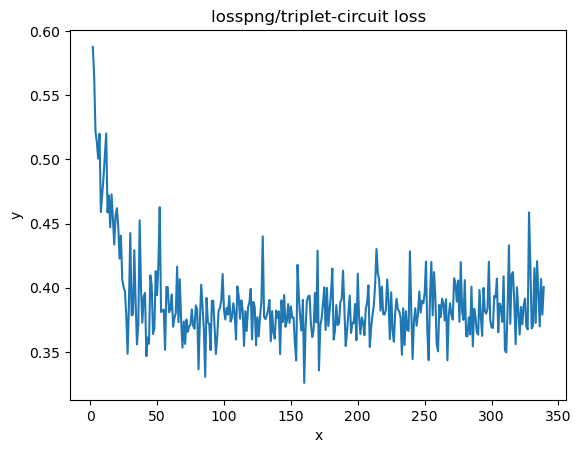

In [33]:
trainer.draw_loss('loss_value2.csv','triplet-circuit loss')

In [34]:
trainer.draw_loss('train_loss.csv','triplet-DFG-final loss')

EmptyDataError: No columns to parse from file

保存模型

In [35]:
# torch.save(model.state_dict(), "triplet_model.pt")
torch.save(model.state_dict(), "triplet_model_v1_itc99.pt")

## 3 评估

In [36]:
test_loss, test_labels, zz, test_preds = trainer.inference(test_loader)

100%|██████████| 32/32 [00:01<00:00, 19.24it/s]


In [37]:
trainer.metric_calc(test_loss,  test_labels,  test_preds,  header="test ")

test  loss: 0.030159, test  accuracy: 0.9950, test  f1 score: 0.9784, test  confusion_matrix: [[1779   10], [   0  227]], test  precision: 0.9578, test  recall: 1.0000


In [38]:
auc = roc_auc_score(test_labels, zz)

In [39]:
auc

0.9996848090262815

In [40]:
fpr, tpr, thresholds = roc_curve(test_labels, zz)
maxindex = (tpr - fpr).tolist().index(max(tpr - fpr))
thresholds[maxindex]

0.8008226

这个阈值很大，大于0.8，那如果还按0.5分类，FPR就会变大，导致有很多负样本被分类为正样本

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

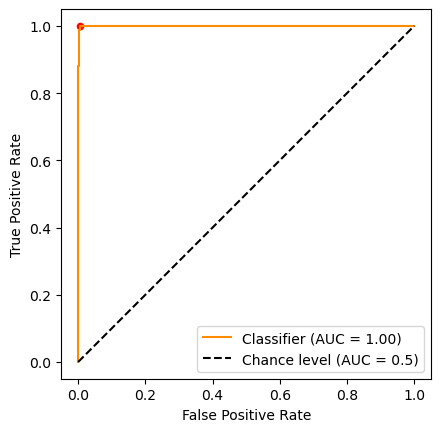

In [42]:
RocCurveDisplay.from_predictions(
    test_labels,
    zz,
    # name=f"HW2VEC",
    color="darkorange",
    plot_chance_level=True,
)
plt.axis("square")
plt.scatter(fpr[maxindex], tpr[maxindex], color='red', s=20)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
# plt.title("One-vs-Rest ROC curves:\nVirginica vs (Setosa & Versicolor)")
plt.legend()
plt.show()

ROC图放论文上应该是把两种方法的ROC曲线放一张图里比较好，看啥时候弄一下，好像还不是很好弄？

## 4 计算图可视化

In [43]:
from torchviz import make_dot

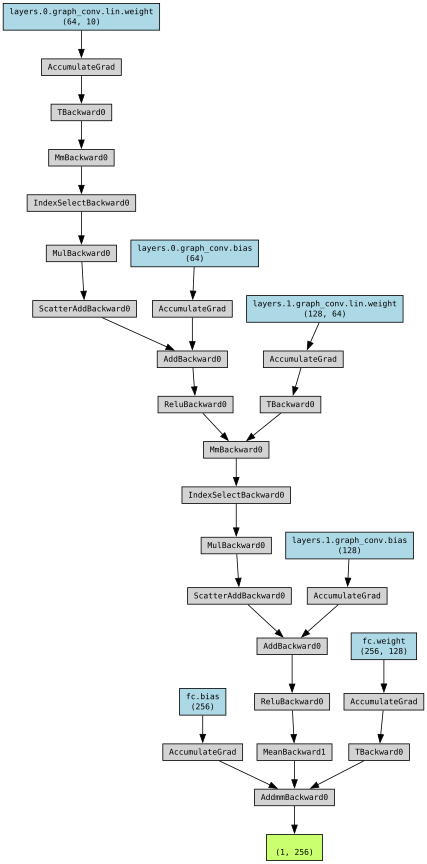

In [44]:
trainer.model.eval()
# trainer.model.train()

data = dataset[0]
data.to(cfg.device)
label = data.label
# print(label.type)
embed_x, _ = trainer.model.embed_graph(data.x, data.edge_index, data.batch)
embed_x = trainer.model.mlp(embed_x)

make_dot(embed_x, params=dict(model.named_parameters()))

## 5 可视化

In [45]:
import umap
import matplotlib.pyplot as plt
from cycler import cycler

需要先获取所有样本的特征，得按batch收集一下吧

In [46]:
embeddings = []
labels = []

In [47]:
with torch.no_grad():
    trainer.model.eval()

    for data in train_loader:
        data.to(cfg.device)
        label = data.label
        # print(label.type)
        embed_x, _ = trainer.model.embed_graph(data.x, data.edge_index, data.batch)
        embed_x = trainer.model.mlp(embed_x)
        embeddings.append(embed_x)
        labels.append(label)

In [48]:
embeddingszz = torch.stack(embeddings[:-1], dim=3)

IndexError: Dimension out of range (expected to be in range of [-3, 2], but got 3)

In [ ]:
zz = torch.cat([embeddings[0], embeddings[1]])

In [ ]:
zz.shape

torch.Size([128, 256])

In [ ]:
embeddingszz = embeddings[0]
for e in embeddings[1:]:
    embeddingszz = torch.cat([embeddingszz, e])

In [ ]:
embeddingszz.shape

torch.Size([305, 256])

In [ ]:
labelszz = labels[0]
for e in labels[1:]:
    labelszz = torch.cat([labelszz, e])

In [ ]:
labelszz.shape

torch.Size([305])

In [ ]:
reducer = umap.UMAP()
umap_embeddings = reducer.fit_transform(embeddingszz.cpu().numpy())

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


得把张量从显卡移到CPU，再转为`NumPy`类型

In [ ]:
umap_embeddings.shape

(305, 2)

In [ ]:
labels = labelszz.cpu().numpy()

In [ ]:
labels

array([0, 2, 7, 8, 5, 8, 5, 6, 4, 0, 4, 1, 0, 7, 8, 8, 4, 3, 6, 5, 3, 1,
       7, 1, 7, 3, 4, 8, 6, 2, 0, 3, 0, 3, 4, 7, 7, 8, 7, 1, 6, 5, 5, 0,
       5, 1, 6, 1, 0, 4, 8, 8, 1, 8, 5, 6, 1, 2, 4, 6, 7, 0, 3, 7, 7, 1,
       7, 3, 3, 6, 3, 0, 6, 0, 6, 8, 6, 4, 8, 8, 0, 0, 7, 7, 0, 7, 5, 3,
       5, 2, 1, 7, 1, 1, 2, 7, 4, 1, 3, 0, 6, 0, 1, 6, 3, 3, 2, 2, 4, 0,
       0, 0, 5, 5, 2, 3, 6, 3, 0, 0, 6, 0, 2, 1, 2, 5, 2, 6, 5, 8, 0, 0,
       4, 0, 4, 0, 1, 0, 5, 1, 7, 7, 3, 5, 4, 0, 1, 7, 8, 5, 8, 3, 8, 0,
       1, 5, 4, 0, 1, 0, 7, 0, 8, 4, 2, 0, 0, 2, 5, 0, 1, 8, 5, 2, 5, 2,
       2, 1, 6, 2, 6, 7, 3, 5, 7, 2, 3, 8, 2, 2, 0, 8, 7, 4, 8, 3, 5, 2,
       6, 0, 1, 2, 1, 7, 8, 5, 0, 1, 2, 6, 7, 8, 2, 0, 7, 7, 5, 7, 3, 4,
       3, 5, 4, 0, 8, 5, 7, 7, 7, 6, 1, 7, 0, 2, 1, 0, 4, 3, 8, 0, 7, 4,
       2, 8, 3, 0, 0, 7, 5, 8, 8, 0, 1, 0, 5, 1, 0, 7, 2, 7, 0, 5, 3, 5,
       4, 5, 3, 6, 1, 0, 6, 2, 6, 8, 4, 8, 7, 5, 0, 3, 0, 2, 4, 7, 7, 8,
       1, 8, 3, 8, 3, 4, 3, 2, 4, 0, 3, 0, 1, 3, 3,

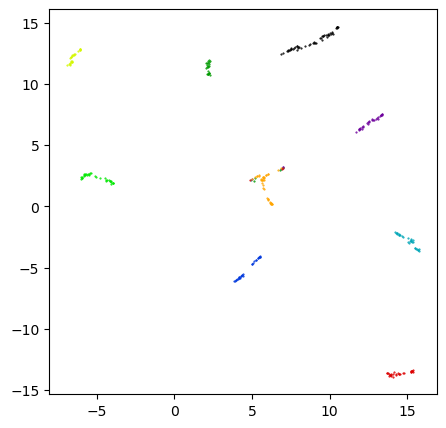

In [ ]:
label_set = np.unique(labels)
num_classes = len(label_set)
# print(num_classes, label_set)
plt.figure(figsize=(5, 5))
plt.gca().set_prop_cycle(
    cycler(
        "color", [plt.cm.nipy_spectral(i) for i in np.linspace(0, 0.9, num_classes)]
    )
)
for i in range(num_classes):
    idx = labels == label_set[i]
    # print(idx)
    plt.plot(umap_embeddings[idx, 0], umap_embeddings[idx, 1], ".", markersize=1)
# plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
plt.show()

虽然效果不如PML的栗子那么明显，但是和umap官网的样例其实是很相似的，调一调图，是可以放论文里的吧？

之后可以看怎么加个图例

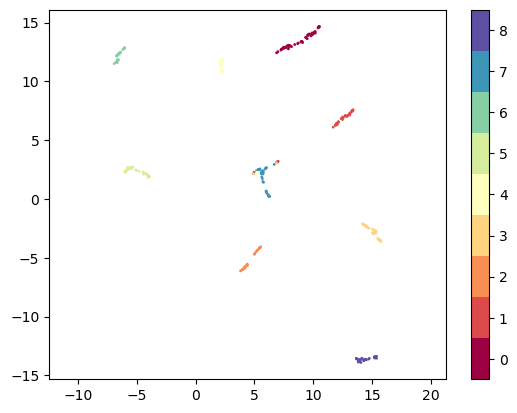

In [ ]:
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], c=labels, cmap='Spectral', s=1, alpha=1)
plt.gca().set_aspect('equal', 'datalim')
plt.colorbar(boundaries=np.arange(10)-0.5).set_ticks(np.arange(num_classes))
# plt.title('UMAP projection of the Digits dataset', fontsize=24)

好多参数不知道是啥意思，论文中确定要用的话还可以再尝试美观一下。

现在足够说明度量学习的有效性了吧